# 04 — Machine-learning models

**Question:** does GPS ground deformation improve weekly forecasts beyond what past seismicity already gives?

Phase 5 (`03_baselines`) found that the paper's uplift-driven model tracks the long-term level of seismicity, while a 4-week rolling mean follows swarms. Here we combine both kinds of information in one model and, crucially, compare the **same model with and without GPS features** (an ablation): the difference is what GPS adds.

**Plan:**
1. Features, and a check that none of them uses future data. *(this step)*
2. Poisson regression (GLM), with and without GPS.
3. LightGBM (gradient-boosted trees), with and without GPS.
4. P(M ≥ 3 next week): from the count models, and as direct classifiers.
5. SHAP explanations of the best model.

Same evaluation as phase 5: test weeks January 2020 – December 2025 (312 weeks, plus 2023–2025 separately), walk-forward with expanding window. Training starts in 2013 (before that, uplift is mostly GPS noise and nearly every week is empty). **The bar:** Poisson deviance 14.8 (2020–2025) / 24.1 (2023–2025), Brier 0.107, log-loss 0.335.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.features import (ALL_FEATURES, COMBINED_FEATURES, GPS_FEATURES, SEISMIC_FEATURES,
                          build_features, check_no_lookahead, station_scales)

events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")
table = build_features(events, gps, start="2005-01-03", end="2025-12-28")
TRAIN_START, TEST_START, TEST_END = "2013-01-07", "2020-01-06", "2025-12-22"
print(f"{len(table)} weeks, {len(ALL_FEATURES)} features")

1095 weeks, 19 features


## 1. Features

All features for the week starting on Monday *w* use data up to the Sunday before (`src/features.py`):

| Group | Feature | Meaning |
|---|---|---|
| Seismicity | `log_count_1w` | log(1 + events with M ≥ 0.6 last week) |
| | `log_mean_2w`, `log_mean_4w`, `log_mean_12w` | log(1 + mean weekly count over the last 2, 4, 12 weeks) |
| | `log_max_4w` | log(1 + largest weekly count in the last 4 weeks): catches swarms |
| | `log_count_m2_4w`, `log_count_m25_4w` | log(1 + events with M ≥ 2, M ≥ 2.5 in the last 4 weeks) |
| | `weeks_since_large` | weeks since the last week with an M ≥ 3 (capped at 260) |
| | `log_N` | log(1 + cumulative count since 2005) |
| GPS | `delta_rite` | RITE uplift since Jan 2005 (cm), 7-day mean |
| | `rate_rite_7d` … `rate_rite_90d` | RITE uplift rate over the last 7, 14, 28, 90 days (cm/year) |
| | `accel_rite` | change of the 28-day rate over 4 weeks |
| | `rate_near_28d` | shared 28-day rate of the 7 near stations (RITE, SOLO, PIS1, STRZ, ARFE, IPPO, ASTR), in RITE units |
| | `rate_far_28d` | mean 28-day rate of 4 far stations (LICO, FRUL, NAMM, MAFE): mostly common noise |
| Combined | `log_N_x_uplift` | log(1 + N × uplift per week): the paper's "rate ∝ N × uplift rate" |
| | `log_paper_mu` | log(1 + the paper's weekly forecast μ, from `03_baselines` section 4) |

**The near-station rate.** Station *i* moves about *sᵢ* times as much as RITE (one source, one shape). Its rate is then about *sᵢ·S*, where *S* is the shared rate. The least-squares estimate from the stations reporting that day is S = Σ sᵢ·rateᵢ / Σ sᵢ². Stations that move little get little weight, so their noise isn't amplified. The scales *sᵢ* are fixed constants, estimated from 2017–2019 (before the test period):

In [2]:
station_scales(gps).round(3).to_frame().T

,RITE,SOLO,PIS1,STRZ,ARFE,IPPO,ASTR
scale,1.0,0.69,0.559,0.571,0.442,0.159,0.231


**Checking for look-ahead.** The most common way to fool yourself in forecasting is a feature that accidentally uses the week being forecast (or later). `check_no_lookahead` deletes all events and GPS data from week *w* onwards, rebuilds the features, and compares week *w*'s row with the full-data version. Any feature that peeks would change.

In [3]:
check_weeks = ["2013-01-07", "2016-06-06", "2020-01-06", "2023-09-25", "2024-05-20", "2025-02-17", "2025-12-22"]
check_no_lookahead(events, gps, "2005-01-03", "2025-12-28", check_weeks, full=table)

,max_abs_difference,features_compared
2013-01-07,0.0,20.0
2016-06-06,0.0,20.0
2020-01-06,0.0,21.0
2023-09-25,0.0,21.0
2024-05-20,0.0,21.0
2025-02-17,0.0,21.0
2025-12-22,0.0,21.0


Every feature is identical: none uses data from its own week or later. (19 of the 19 features are compared; the station scales are the fixed 2017–2019 constants in both cases.)

To show that the check would catch a mistake, here is a deliberately *leaky* feature, the week's own event count, computed both ways:

In [4]:
from src.series import event_counts

def leaky_feature(evts, week):
    """WRONG on purpose: log(1 + this week's own count)."""
    counts = event_counts(evts, "W", mc=0.6, start="2005-01-03", end="2025-12-28")
    return np.log1p(counts.get(pd.Timestamp(week, tz="UTC"), 0))

for week in ["2024-05-20", "2025-02-17"]:
    cut = pd.Timestamp(week, tz="UTC")
    print(f"{week}: full data {leaky_feature(events, week):.2f}, "
          f"data cut at the week {leaky_feature(events[events['time'] < cut], week):.2f}  -> caught")

2024-05-20: full data 5.08, data cut at the week 0.00  -> caught
2025-02-17: full data 5.81, data cut at the week 0.00  -> caught


**How do the features relate to next week's count?** Rank (Spearman) correlation of each feature with log(1 + count) over the training-and-test span 2013–2025. This is only a first look: correlations include the shared upward trend, and models will combine features.

In [5]:
span = table.loc[TRAIN_START:TEST_END]
target = np.log1p(span["count"])
corr = span[ALL_FEATURES].corrwith(target, method="spearman").rename("spearman_with_log_count")
group = pd.Series({f: g for g, fs in [("seismicity", SEISMIC_FEATURES), ("GPS", GPS_FEATURES),
                                      ("combined", COMBINED_FEATURES)] for f in fs}, name="group")
pd.concat([group, corr.round(2)], axis=1).sort_values("spearman_with_log_count", ascending=False)

,group,spearman_with_log_count
delta_rite,GPS,0.79
log_N,seismicity,0.78
log_mean_4w,seismicity,0.77
log_mean_12w,seismicity,0.76
log_max_4w,seismicity,0.75
log_mean_2w,seismicity,0.75
log_N_x_uplift,combined,0.74
log_count_1w,seismicity,0.73
log_paper_mu,combined,0.73
rate_rite_90d,GPS,0.70


In [6]:
# How similar are the GPS features to each other? (Spearman, 2013-2025)
span[GPS_FEATURES].corr(method="spearman").round(2)

,delta_rite,rate_rite_7d,rate_rite_14d,rate_rite_28d,rate_rite_90d,accel_rite,rate_near_28d,rate_far_28d
delta_rite,1.00,0.18,0.37,0.59,0.76,0.03,0.52,0.03
rate_rite_7d,0.18,1.00,0.41,0.22,0.16,0.12,0.23,0.12
rate_rite_14d,0.37,0.41,1.00,0.58,0.39,0.32,0.57,0.28
rate_rite_28d,0.59,0.22,0.58,1.00,0.69,0.51,0.97,0.46
rate_rite_90d,0.76,0.16,0.39,0.69,1.00,-0.07,0.61,0.01
accel_rite,0.03,0.12,0.32,0.51,-0.07,1.00,0.56,0.54
rate_near_28d,0.52,0.23,0.57,0.97,0.61,0.56,1.00,0.59
rate_far_28d,0.03,0.12,0.28,0.46,0.01,0.54,0.59,1.00


**What the features show:**

- **No look-ahead:** all 19 features are identical when every bit of data from the forecast week onwards is deleted, at 7 weeks from 2013 to the last test week; the deliberately leaky feature is caught at once.
- **Slow features correlate most** with next week's count: uplift level (`delta_rite`, 0.79), cumulative count (`log_N`, 0.78), and recent mean counts (0.73–0.77). Much of this is the shared upward trend from 2013 to 2025, so these numbers don't say what helps *week to week*.
- **Short-window uplift rates carry less:** 0.56 for the 28-day rate, 0.36 for 14 days, 0.20 for 7 days. Shorter windows are noisier.
- **Some GPS features are mostly noise or duplicates:**
  - The near-station rate is almost the same as RITE's 28-day rate (correlation 0.97), so averaging stations adds little beyond RITE (as phase 4 suggested).
  - The far-station rate correlates 0.46 with RITE's 28-day rate although the far stations barely move: that's GPS noise common to the whole network (for example seasonal or processing effects). And the acceleration correlates 0.54 with the far-station rate, so it is largely that common noise too.
  - This suggests a cleaner signal for later: RITE's rate *minus* the far-station rate. We'll see first whether the models find the GPS features useful as they are.
- `weeks_since_large` correlates −0.74: long gaps since the last M ≥ 3 mean quiet periods (and the early years, when there were none at all).

## 2. Poisson regression (GLM), with and without GPS

A Poisson GLM models log(expected count) as a weighted sum of the features: the same kind of model as the paper's rate equation, but with many inputs. An **L2 penalty** shrinks the weights towards zero to avoid overfitting the ~360–700 training weeks: the stronger the penalty, the closer the weights stay to zero.

**How each forecast is made** (`src/models.py`), with the first test week of 2023 (Monday 2 January) as the example:

1. **Training data:** every week from 7 January 2013 up to the last complete week before the forecast (the week starting 26 December 2022). Each row is one *week*: its count of events with M ≥ 0.6 is the target, its features are the inputs. Weeks with a missing feature (a few GPS gaps) are dropped.
2. **Standardise:** each feature's mean and standard deviation are computed on these training weeks only, and the features are rescaled to mean 0 and standard deviation 1. This makes the weights comparable, and the scaling uses only the past.
3. **Fit** the weights by maximising the Poisson likelihood, with the penalty chosen for 2023 (below).
4. **Predict:** standardise the 2 January week's features with the same means and standard deviations and compute the expected count. A missing feature in the forecast week takes the training median.

For the next week (9 January 2023) everything is repeated from scratch with one more training week, and so on: the weights are refitted before every test week.

**How the penalty is chosen:** once a year, at the first test week of that year, never using test weeks, by a **grid search over time-ordered folds** (scikit-learn's `GridSearchCV` with `TimeSeriesSplit`; `tune` in `src/models.py`). For 2023, the training weeks available then (2013 to 26 December 2022) are split into three folds, each validating on one year with a model trained only on the years before it:

| Fold | Trained on | Validated on |
|---|---|---|
| 1 | 2013 – 2019 | 2020 |
| 2 | 2013 – 2020 | 2021 |
| 3 | 2013 – 2021 | 2022 |

For each candidate penalty (0.001, 0.01, 0.1, 0.3, 1, 3, 10, 30), a model is fitted in each fold and scored on its validation year by Poisson deviance (our own function, with the same 0.1 floor as the test scores). The penalty with the lowest **mean over the three folds** is used for every forecast in 2023. So the penalty is chosen by asking: *which penalty would have made the best forecasts in each of the last three years, with models trained only on earlier data?* Averaging three years makes the choice less sensitive to a single swarm than one validation year would be.

Two points to be careful about:

- **Folds must be time-ordered.** `GridSearchCV`'s default (k-fold) would mix past and future, training on 2022 to "predict" 2020, which is exactly the leakage the whole evaluation avoids. `TimeSeriesSplit` only ever validates on weeks after the training weeks.
- **Simplification:** within each fold the model is fitted once and then predicts its whole validation year, rather than being refitted week by week as in the real test. It only needs to rank the candidates, but tuning scores aren't directly comparable with test scores.

In one line: **every forecast in 2023 uses weights trained on all weeks from 2013 up to the week before it, with a penalty chosen by how well models trained on earlier data forecast 2020, 2021 and 2022.** LightGBM (section 3) follows the same scheme, tuning tree settings instead of the penalty.

Three feature sets:

- **seismic:** past seismicity only (9 features);
- **seismic + GPS:** adds the 8 GPS features;
- **all:** adds the 2 combined features too (N × uplift, the paper's μ).

**Is a difference real?** Scores are averages over 312 weeks, and a few swarm weeks dominate them. So for pairs of models we compute the per-week difference in deviance and a 95% interval by a *block bootstrap*: resample blocks of 8 consecutive weeks (swarms span several weeks) 2,000 times. If the interval contains 0, we can't tell the two models apart.

In [7]:
import warnings

from src.baselines import make_rolling_mean, persistence
from src.evaluation import (count_scores, paired_difference, walk_forward, weekly_poisson_deviance)
from src.models import GLM_ALPHAS, _training_rows, glm_coefficients, make_glm_forecaster

warnings.filterwarnings("ignore", category=RuntimeWarning)
test = table.loc[TEST_START:TEST_END]
recent = test.index >= "2023-01-01"
feature_sets = {"glm_seismic": SEISMIC_FEATURES,
                "glm_seismic_gps": SEISMIC_FEATURES + GPS_FEATURES,
                "glm_all": ALL_FEATURES}

count_forecasts = {"persistence": walk_forward(table, persistence, TEST_START, TEST_END),
                   "rolling_mean_4w": walk_forward(table, make_rolling_mean(4), TEST_START, TEST_END)}
glm_forecasters = {}
for name, features in feature_sets.items():
    glm_forecasters[name] = make_glm_forecaster(features, name)
    count_forecasts[name] = walk_forward(table, glm_forecasters[name], TEST_START, TEST_END)

pd.concat({
    "2020–2025": count_scores(test["count"], count_forecasts),
    "2023–2025": count_scores(test["count"][recent], {n: f[recent] for n, f in count_forecasts.items()}),
}, axis=1).round(2)

2020–2025               2023–2025       
                poisson_deviance    mae poisson_deviance    mae
persistence                15.99  12.16            24.11  20.70
rolling_mean_4w            14.81  12.07            25.35  21.26
glm_seismic                13.39  11.45            22.46  20.06
glm_seismic_gps            13.60  11.49            23.04  20.19
glm_all                    13.66  11.67            23.11  20.55

In [8]:
# Penalty chosen each year (larger = stronger shrinkage); grid: GLM_ALPHAS.
pd.DataFrame({name: f.chosen for name, f in glm_forecasters.items()})

,glm_seismic,glm_seismic_gps,glm_all
2020,1.0,3.0,3.0
2021,3.0,3.0,3.0
2022,3.0,3.0,3.0
2023,1.0,3.0,3.0
2024,1.0,3.0,3.0
2025,1.0,3.0,3.0


In [9]:
# The grid search behind the 2023 choice for the full model: Poisson deviance of each
# candidate penalty in each validation year (fold 1 = 2020, 2 = 2021, 3 = 2022), and the mean.
from src.models import tuning_table

tuning_table(glm_forecasters["glm_all"].tuning[2023], "poissonregressor__alpha").round(2)

,fold 1,fold 2,fold 3,mean
alpha,,,,
0.001,11.51,16.85,5.83,11.40
0.010,10.99,7.11,5.64,7.91
0.100,8.73,5.36,5.23,6.44
0.300,6.95,4.55,5.07,5.52
1.000,5.65,3.63,4.92,4.73
3.000,5.41,3.15,5.18,4.58
10.000,6.13,3.45,6.69,5.42
30.000,7.09,4.47,9.39,6.98


In [10]:
per_week = {name: weekly_poisson_deviance(test["count"], f) for name, f in count_forecasts.items()}
pairs = [("glm_all", "glm_seismic", "GPS + combined added to seismic"),
         ("glm_seismic_gps", "glm_seismic", "GPS added to seismic"),
         ("glm_seismic", "rolling_mean_4w", "seismic GLM against best baseline"),
         ("glm_all", "rolling_mean_4w", "full GLM against best baseline")]
pd.DataFrame({label: paired_difference(per_week[a], per_week[b]) for a, b, label in pairs}).T.round(2)

,mean_difference,ci_low,ci_high
GPS + combined added to seismic,0.27,-0.53,1.06
GPS added to seismic,0.21,-0.58,0.98
seismic GLM against best baseline,-1.42,-3.77,0.34
full GLM against best baseline,-1.15,-3.86,0.88


**What the full model learned.** Coefficients of the GLM with all features, fitted on 2013–2025 with the penalty chosen for 2025. Each coefficient is per standard deviation of its feature: +0.3 means one standard deviation more multiplies the expected count by e^0.3 ≈ 1.35, other features fixed. Correlated features share their weight, so individual values should be read with care.

In [11]:
final_train = _training_rows(table.loc[:TEST_END], ALL_FEATURES)
coefs = glm_coefficients(final_train, ALL_FEATURES, glm_forecasters["glm_all"].chosen[2025])
group = pd.Series({f: g for g, fs in [("seismicity", SEISMIC_FEATURES), ("GPS", GPS_FEATURES),
                                      ("combined", COMBINED_FEATURES)] for f in fs}, name="group")
pd.concat([group, coefs.round(3)], axis=1).sort_values("coefficient", key=abs, ascending=False)

,group,coefficient
log_count_1w,seismicity,0.286
log_mean_2w,seismicity,0.193
delta_rite,GPS,0.159
log_N,seismicity,0.149
weeks_since_large,seismicity,-0.143
log_mean_4w,seismicity,0.132
rate_rite_7d,GPS,0.115
log_max_4w,seismicity,0.112
log_paper_mu,combined,0.081
log_N_x_uplift,combined,0.076


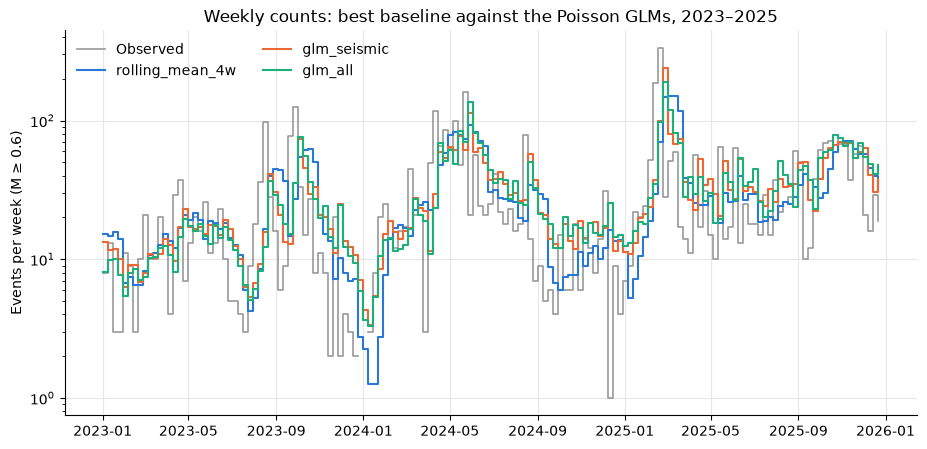

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
shown = test.loc["2023-01-01":]
ax.plot(shown.index, shown["count"].where(shown["count"] > 0), drawstyle="steps-post", color="0.6",
        linewidth=1.2, label="Observed")
for name, colour in [("rolling_mean_4w", "#2a78d6"), ("glm_seismic", "#eb6834"), ("glm_all", "#1baf7a")]:
    f = count_forecasts[name].loc["2023-01-01":]
    ax.plot(f.index, f, drawstyle="steps-post", linewidth=1.5, color=colour, label=name)
ax.set_yscale("log")
ax.set_ylabel("Events per week (M ≥ 0.6)")
ax.set_title("Weekly counts: best baseline against the Poisson GLMs, 2023–2025")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

**What the GLMs show:**

- **The GLM beats the bar, on seismicity alone.** With past seismicity only, its Poisson deviance is 13.4 (2020–2025) and 22.5 (2023–2025), against the best baselines' 14.8 and 24.1; its MAE is also lower (11.5 against 12.1). It reacts more strongly to last week's count than the 4-week mean (largest coefficient), so it follows a swarm sooner, but it also leans on the longer-term level.
- **But the gain is uncertain:** the block-bootstrap interval for the seismic GLM against the 4-week mean is −3.8 to +0.3 per week. It includes 0, so with these 312 weeks we can't be confident it is really better.
- **Adding GPS doesn't help:** with GPS features the deviance is 13.6, with GPS and combined features 13.7, slightly *worse* than seismicity alone; the differences (+0.21 and +0.27 per week, intervals about −0.6 to +1.0) are indistinguishable from zero. The penalty chosen with GPS is also stronger (3 every year, against mostly 1 for seismicity alone), a sign that the extra features mostly add noise to fit.
- **The tuning is more stable over three validation years.** An earlier version validated on the last year only; its choices jumped between 0.1 and 3 and its scores were almost the same (seismic GLM 13.3). For 2023, the table above shows why averaging helps: 2022 alone would pick a penalty of 1, the 2021 fold prefers 3, and the mean settles on 3. Very weak penalties (0.001, 0.01) do badly in every fold: without shrinkage the model overfits.
- **The fitted weights tell the same story.** The largest are on recent counts (last week 0.29, last 2 weeks 0.19). Among GPS features, the uplift level (`delta_rite`, 0.16) mostly duplicates the long-term trend already in `log_N`, and the 7-day uplift rate gets a small weight (0.12). The paper-inspired combined features get 0.08 each.

**So far, the answer to the research question for linear models:** once recent seismicity is known, GPS uplift adds no measurable skill to next week's count. Next: LightGBM, which can capture interactions (for example, uplift mattering only during swarms) that a linear model can't.

## 3. LightGBM, with and without GPS

LightGBM builds an ensemble of small decision trees, each correcting the errors of the previous ones (gradient boosting). With a **Poisson objective** it models log(expected count), like the GLM, but as a sum of tree outputs instead of a weighted sum of features. So it can capture **non-linear effects** (a feature that only matters above some value) and **interactions** (for example uplift mattering only during a swarm), which a GLM can't.

Same training scheme as the GLM: refitted before every test week on all weeks from 2013; settings re-tuned once a year by grid search over the three previous years. Differences:

- No standardisation (trees only use the order of values) and no filling of missing values (LightGBM sends a missing value down whichever branch fitted best in training), so weeks with GPS gaps are kept.
- The grid (`LGBM_GRID`, 36 combinations): number of trees (50, 100, 300), leaves per tree (2, 4, 8; 2 leaves means one split per tree, so no interactions), the fewest training weeks per leaf (10, 30), and an L2 penalty on leaf values (0, 5). Learning rate 0.05, seed fixed. A first grid with larger trees (4–15 leaves, 100–300 trees) was tuned to its smallest values almost every year, so it was extended downwards.

In [13]:
from src.models import LGBM_GRID, make_lgbm_forecaster

lgbm_forecasters = {}
for name, features in {"lgbm_seismic": SEISMIC_FEATURES, "lgbm_seismic_gps": SEISMIC_FEATURES + GPS_FEATURES,
                       "lgbm_all": ALL_FEATURES}.items():
    lgbm_forecasters[name] = make_lgbm_forecaster(features, name)
    count_forecasts[name] = walk_forward(table, lgbm_forecasters[name], TEST_START, TEST_END)

shown_models = ["persistence", "rolling_mean_4w", "glm_seismic", "glm_all", "lgbm_seismic", "lgbm_seismic_gps", "lgbm_all"]
pd.concat({
    "2020–2025": count_scores(test["count"], {n: count_forecasts[n] for n in shown_models}),
    "2023–2025": count_scores(test["count"][recent], {n: count_forecasts[n][recent] for n in shown_models}),
}, axis=1).round(2)

2020–2025               2023–2025       
                 poisson_deviance    mae poisson_deviance    mae
persistence                 15.99  12.16            24.11  20.70
rolling_mean_4w             14.81  12.07            25.35  21.26
glm_seismic                 13.39  11.45            22.46  20.06
glm_all                     13.66  11.67            23.11  20.55
lgbm_seismic                14.84  12.00            25.16  20.97
lgbm_seismic_gps            13.68  11.94            22.38  20.86
lgbm_all                    15.10  12.39            25.22  21.81

In [14]:
# Settings chosen each year: (number of trees, leaves per tree, fewest weeks per leaf, leaf penalty).
pd.DataFrame({name: {year: (p["n_estimators"], p["num_leaves"], p["min_child_samples"], p["reg_lambda"])
                     for year, p in f.chosen.items()} for name, f in lgbm_forecasters.items()})

,lgbm_seismic,lgbm_seismic_gps,lgbm_all
2020,"(100, 2, 10, 0.0)","(100, 2, 10, 0.0)","(100, 2, 10, 0.0)"
2021,"(300, 2, 10, 5.0)","(100, 8, 30, 0.0)","(100, 4, 10, 0.0)"
2022,"(100, 2, 10, 0.0)","(100, 2, 30, 5.0)","(100, 2, 30, 5.0)"
2023,"(100, 2, 10, 0.0)","(300, 2, 30, 0.0)","(300, 2, 30, 0.0)"
2024,"(300, 2, 10, 5.0)","(300, 2, 10, 5.0)","(300, 2, 10, 5.0)"
2025,"(100, 8, 30, 5.0)","(300, 2, 30, 5.0)","(100, 4, 30, 0.0)"


In [15]:
per_week = {name: weekly_poisson_deviance(test["count"], f) for name, f in count_forecasts.items()}
pairs = [("lgbm_all", "lgbm_seismic", "GPS + combined added to seismic (LightGBM)"),
         ("lgbm_seismic_gps", "lgbm_seismic", "GPS added to seismic (LightGBM)"),
         ("lgbm_seismic", "glm_seismic", "LightGBM against GLM (seismic)"),
         ("lgbm_seismic", "rolling_mean_4w", "LightGBM (seismic) against best baseline")]
pd.DataFrame({label: paired_difference(per_week[a], per_week[b]) for a, b, label in pairs}).T.round(2)

,mean_difference,ci_low,ci_high
GPS + combined added to seismic (LightGBM),0.26,-1.47,2.35
GPS added to seismic (LightGBM),-1.15,-3.80,1.07
LightGBM against GLM (seismic),1.44,0.17,3.01
LightGBM (seismic) against best baseline,0.03,-1.73,1.88


In [16]:
# Mean weekly forecast per year against the observed mean: does LightGBM fall behind the growth?
pd.DataFrame({"observed": test["count"], "glm_seismic": count_forecasts["glm_seismic"],
              "lgbm_seismic": count_forecasts["lgbm_seismic"]}).groupby(test.index.year).mean().round(1)

,observed,glm_seismic,lgbm_seismic
period_start,,,
2020,2.8,1.8,1.9
2021,3.2,2.4,3.7
2022,5.8,3.9,3.7
2023,17.7,17.0,13.3
2024,27.4,29.1,27.6
2025,42.9,45.4,42.7


**What LightGBM shows:**

- **It doesn't beat the GLM.** On seismicity alone its deviance is 14.8 (2020–2025), the same as the 4-week rolling mean and clearly worse than the GLM's 13.4: the interval for the gap (+0.2 to +3.0 per week) excludes zero, so this one is a real difference.
- **The data prefer the simplest trees.** The tuning nearly always picks trees with **2 leaves** (one split each), which means an additive model with no interactions at all, and often only 100 trees. A first grid with larger trees was tuned to its smallest values almost every year. The ~600 training weeks are too few and too noisy to learn interactions; and step-shaped trees fit a smooth multiplicative response less well than the GLM's log-linear one.
- **It falls behind the growth in 2023:** mean forecast 13.3 events/week against 17.7 observed (GLM: 17.0). That year the weekly count went above anything in the training data six times; a tree model can only partly forecast values it has never seen, while the GLM extrapolates its log-linear trend.
- **The GPS result is unstable.** Adding GPS features *lowered* LightGBM's deviance (14.8 → 13.7), but adding GPS *and* the two combined features *raised* it (15.1). The intervals (−3.8 to +1.1 and −1.5 to +2.4 per week) both include zero, and two closely related feature sets pointing in opposite directions is a sign of noise, not of a real effect: small changes in features change which settings the yearly tuning picks, and with 312 swarm-dominated weeks that moves the score by a point or more.

**So far, across both model families:** the best model is the GLM on seismicity alone (deviance 13.4 / 22.5), and no model shows a robust gain from GPS. Next: the M ≥ 3 target (step 4), where uplift might still matter for the probability of *larger* events even if not for counts.

## 4. P(at least one M ≥ 3 next week)

Two routes (`src/models.py`):

- **(a) From a count forecast,** as in phase 5: P = 1 − exp(−μ × share), where μ is a model's expected count and *share* is the fraction of events with M ≥ 0.6 that reached M ≥ 3 over the last 3 years (`share_large`). We use the 4-week rolling mean (the phase 5 baseline), the seismic GLM and the full GLM.
- **(b) Direct classifiers** of "M ≥ 3 next week, yes or no": logistic regression (standardised features, L2 penalty C = 0.1) and LightGBM (100 two-leaf trees), each with seismic features only or all features.

**The direct classifiers face a data problem.** Weeks with an M ≥ 3 are rare and recent: the training data has its first in December 2019, its 5th in January 2023 and its 10th only in September 2023. A classifier can't learn from one or two positive weeks, and the yearly tuning can't work when the validation years 2020–2022 contain three positive weeks between them. So the classifiers:

- start only once the training data holds **10 positive weeks** (from the week of 25 September 2023); before that they use the 52-week climatology;
- use **fixed, conservative settings** rather than tuned ones;
- don't re-weight the classes: that would help catch rare positives but distort the probabilities, which are what we score.

Because of this, scores are shown for 2020–2025 and for **2024–2025**, when the classifiers are active throughout (30 of 104 weeks had an M ≥ 3). **The bar:** Brier 0.107, log-loss 0.335 (2020–2025).

In [17]:
from src.baselines import make_climatology
from src.evaluation import calibration_table, probability_scores
from src.models import make_classifier_forecaster, share_large

share = walk_forward(table, lambda history, current: share_large(history), TEST_START, TEST_END)
prob_forecasts = {"climatology_52w": walk_forward(table, make_climatology(52), TEST_START, TEST_END)}
for name in ["rolling_mean_4w", "glm_seismic", "glm_all"]:
    prob_forecasts[f"from_{name}"] = 1 - np.exp(-count_forecasts[name] * share)

classifiers = {}
for name, features, kind in [("logit_seismic", SEISMIC_FEATURES, "logistic"), ("logit_all", ALL_FEATURES, "logistic"),
                             ("lgbmclf_seismic", SEISMIC_FEATURES, "lgbm"), ("lgbmclf_all", ALL_FEATURES, "lgbm")]:
    classifiers[name] = make_classifier_forecaster(features, name, kind)
    prob_forecasts[name] = walk_forward(table, classifiers[name], TEST_START, TEST_END)
print("Classifiers active from:", {n: f"{c.state['active_from']:%Y-%m-%d}" for n, c in classifiers.items()})

late = test.index >= "2024-01-01"
print(f"Weeks with an M ≥ 3: {int(test['has_large'].sum())} of {len(test)} (2020–2025), "
      f"{int(test['has_large'][late].sum())} of {late.sum()} (2024–2025)")
pd.concat({
    "2020–2025": probability_scores(test["has_large"], prob_forecasts),
    "2024–2025": probability_scores(test["has_large"][late], {n: p[late] for n, p in prob_forecasts.items()}),
}, axis=1).round(3)

Classifiers active from: {'logit_seismic': '2023-09-25', 'logit_all': '2023-09-25', 'lgbmclf_seismic': '2023-09-25', 'lgbmclf_all': '2023-09-25'}
Weeks with an M ≥ 3: 43 of 312 (2020–2025), 30 of 104 (2024–2025)


2020–2025                 2024–2025                
                         brier log_loss mean_p     brier log_loss mean_p
climatology_52w          0.107    0.357  0.118     0.209    0.610  0.279
from_rolling_mean_4w     0.107    0.335  0.150     0.217    0.621  0.357
from_glm_seismic         0.112    0.354  0.157     0.231    0.667  0.389
from_glm_all             0.113    0.355  0.159     0.235    0.671  0.394
logit_seismic            0.106    0.352  0.135     0.211    0.612  0.320
logit_all                0.109    0.360  0.143     0.221    0.637  0.341
lgbmclf_seismic          0.112    0.368  0.135     0.220    0.637  0.314
lgbmclf_all              0.110    0.367  0.127     0.219    0.640  0.295

In [18]:
# Per-week Brier score and log-loss, for paired comparisons.
happened = test["has_large"].astype(float)
clipped = {n: np.clip(p, 1e-3, 1 - 1e-3) for n, p in prob_forecasts.items()}
brier_week = {n: (p - happened) ** 2 for n, p in prob_forecasts.items()}
logloss_week = {n: -(happened * np.log(p) + (1 - happened) * np.log(1 - p)) for n, p in clipped.items()}
pairs = [("logit_all", "logit_seismic", "GPS added (logistic)"),
         ("lgbmclf_all", "lgbmclf_seismic", "GPS added (LightGBM classifier)"),
         ("from_glm_all", "from_glm_seismic", "GPS added (GLM count → probability)"),
         ("logit_seismic", "from_rolling_mean_4w", "logistic (seismic) against the bar"),
         ("from_glm_seismic", "from_rolling_mean_4w", "GLM count → probability against the bar")]
pd.concat({
    "Brier": pd.DataFrame({label: paired_difference(brier_week[a], brier_week[b]) for a, b, label in pairs}).T,
    "log-loss": pd.DataFrame({label: paired_difference(logloss_week[a], logloss_week[b]) for a, b, label in pairs}).T,
}, axis=1).round(4)

Brier                  \
                                        mean_difference  ci_low ci_high   
GPS added (logistic)                             0.0036  0.0007  0.0064   
GPS added (LightGBM classifier)                 -0.0020 -0.0071  0.0031   
GPS added (GLM count → probability)              0.0007 -0.0032  0.0040   
logistic (seismic) against the bar              -0.0008 -0.0064  0.0044   
GLM count → probability against the bar          0.0053  0.0013  0.0097   

                                               log-loss                  
                                        mean_difference  ci_low ci_high  
GPS added (logistic)                             0.0081  0.0014  0.0148  
GPS added (LightGBM classifier)                 -0.0018 -0.0132  0.0105  
GPS added (GLM count → probability)              0.0009 -0.0120  0.0108  
logistic (seismic) against the bar               0.0171 -0.0068  0.0495  
GLM count → probability against the bar          0.0193  0.0075  0.0329

In [19]:
# Calibration in 2024-2025: mean forecast against how often an M >= 3 happened.
pd.concat({name: calibration_table(test["has_large"][late], prob_forecasts[name][late], bins=(0, 0.1, 0.2, 0.3, 0.5, 1.0))
           for name in ["from_rolling_mean_4w", "from_glm_seismic", "logit_seismic"]}, axis=1).round(2)

from_rolling_mean_4w                               \
                             weeks mean_forecast observed_share   
forecast_bin                                                      
(-0.001, 0.1]                    8          0.05           0.00   
(0.1, 0.2]                      21          0.15           0.19   
(0.2, 0.3]                      14          0.25           0.36   
(0.3, 0.5]                      38          0.39           0.32   
(0.5, 1.0]                      23          0.67           0.39   

              from_glm_seismic                              logit_seismic  \
                         weeks mean_forecast observed_share         weeks   
forecast_bin                                                                
(-0.001, 0.1]                4          0.06           0.00             9   
(0.1, 0.2]                  19          0.17           0.21            21   
(0.2, 0.3]                  14          0.25           0.21            19   
(0.3, 0.5]                  38          0.40           0.34            39   
(0.5, 1.0]                  29          0.63           0.34            16   

                                            
              mean_forecast observed_share  
forecast_bin                                
(-0.001, 0.1]          0.06           0.11  
(0.1, 0.2]             0.13           0.19  
(0.2, 0.3]             0.26           0.26  
(0.3, 0.5]             0.38           0.31  
(0.5, 1.0]             0.62           0.50

**What the M ≥ 3 forecasts show:**

- **Nothing clearly beats the bar.** The best is the logistic classifier on seismicity alone: Brier 0.106 against the bar's 0.107 (difference −0.0008, interval −0.006 to +0.004), but its log-loss is worse (0.352 against 0.335; interval includes 0). In 2024–2025, when the classifiers are active throughout, the plain 52-week **climatology is as good as anything** (Brier 0.209): forecasting the recent share of weeks with an M ≥ 3, about 28%, is hard to improve on.
- **A better count forecast doesn't give a better probability.** Converting the GLM's counts (which beat the rolling mean for counts) gives *significantly worse* probabilities than converting the rolling mean (Brier +0.005, interval +0.001 to +0.010). The calibration table shows why: weeks where the conversion said more than 50% (mean 63–67%) had an M ≥ 3 only 34–39% of the time. The conversion assumes events are independent, so a big expected count means a near-certain M ≥ 3. But busy weeks are swarms of small events, and an M ≥ 3 doesn't become proportionally more likely. The GLM forecasts larger counts in busy weeks, so it's more over-confident.
- **The direct classifier learns this** and is better calibrated at the top (forecasts above 50%, mean 62%, came true 50% of the time), which is why it does at least as well despite little data.
- **GPS doesn't help.** Adding GPS and combined features makes the logistic classifier *significantly worse* (Brier +0.0036, interval +0.0007 to +0.0064; log-loss +0.008, interval +0.001 to +0.015): with ~25–40 positive weeks, 10 extra features mostly add noise. For the other two routes the difference is indistinguishable from zero.

**So for larger events too, uplift adds nothing measurable to what past seismicity already says, and past seismicity itself adds little to the recent base rate.** Next: SHAP explanations of the models, to see which features they actually rely on.

## 4b. Improving the M ≥ 3 forecasts

Section 4 left two questions: can the models really not beat a naive climatology, or are they set up badly? Two diagnostics help separate *ranking* from *calibration*:

- **ROC AUC:** the probability that a randomly chosen week with an M ≥ 3 got a higher forecast than a randomly chosen week without one. 0.5 means the forecast ranks weeks no better than chance; 1 means perfectly. It ignores whether the probabilities themselves are right, so it can also score raw features.
- **Brier decomposition** (Murphy): Brier = reliability − resolution + uncertainty. *Reliability* is how far the probabilities are from the observed frequencies (lower is better); *resolution* is how well the forecasts separate riskier from safer weeks (higher is better); *uncertainty* depends only on the base rate.

Over 2020–2025, AUC is flattered by the shift from quiet years to busy ones (even climatology scores 0.75): it mostly separates *periods*. **2024–2025, when the rate of M ≥ 3 weeks was roughly steady, is the fair test of week-to-week skill.**

In [20]:
from src.evaluation import ranking_scores

late = test.index >= "2024-01-01"
single_features = {f"feature: {f}": test[f] * (-1 if f == "weeks_since_large" else 1)
                   for f in ["log_mean_4w", "log_count_m2_4w", "weeks_since_large", "rate_rite_28d", "rate_rite_90d", "delta_rite"]}
section4 = {n: prob_forecasts[n] for n in ["climatology_52w", "from_rolling_mean_4w", "logit_seismic", "logit_all"]}
pd.concat({
    "AUC 2020–2025": ranking_scores(test["has_large"], {**section4, **single_features})["auc"],
    "AUC 2024–2025": ranking_scores(test["has_large"][late], {n: p[late] for n, p in {**section4, **single_features}.items()})["auc"],
}, axis=1).round(3)

,AUC 2020–2025,AUC 2024–2025
climatology_52w,0.747,0.467
from_rolling_mean_4w,0.816,0.623
logit_seismic,0.786,0.603
logit_all,0.782,0.585
feature: log_mean_4w,0.827,0.634
feature: log_count_m2_4w,0.795,0.633
feature: weeks_since_large,0.736,0.530
feature: rate_rite_28d,0.642,0.523
feature: rate_rite_90d,0.695,0.501
feature: delta_rite,0.773,0.479


In [21]:
ranking_scores(test["has_large"][late], {n: p[late] for n, p in section4.items()}).round(3)

,auc,reliability,resolution,uncertainty
climatology_52w,0.467,0.007,0.003,0.205
from_rolling_mean_4w,0.623,0.023,0.018,0.205
logit_seismic,0.603,0.014,0.005,0.205
logit_all,0.585,0.021,0.003,0.205


**Diagnosis:**

- Within 2024–2025, **recent counts do rank weeks better than chance** (AUC 0.63 for the 4-week mean count), while **GPS features don't** (0.48–0.52). That fits the physics: magnitudes are close to independent of each other (Gutenberg–Richter), so the chance of an M ≥ 3 depends mostly on how many events there will be, and short-term uplift rates are mostly network noise.
- **The count conversion has information but throws it away:** it has the best resolution (0.018) but the worst reliability (0.023), because assuming independent events makes it over-confident in busy weeks.
- **The section 4 classifiers rank worse (AUC 0.59–0.60) than the single feature they mostly rely on (0.63).** With 9–19 features and only 10–40 positive weeks (a common rule of thumb is 10–20 positive cases per feature), and training from 2013 (which mostly teaches "quiet years against busy years"), they fit noise.

**Changes in this step:**

1. **Recalibrate the conversion** (Platt scaling): learn P = sigmoid(a + b · log μ₄w) from past weeks, where μ₄w is the 4-week mean count. That is a logistic regression on the single feature `log_mean_4w`. It keeps the conversion's ranking but learns how often busy weeks really produce an M ≥ 3.
2. **Lean classifiers:** 2–3 features only, and a mild penalty (C = 1).
3. **A sliding window:** train on the last 156 weeks (3 years) instead of all weeks since 2013, because the relation between features and M ≥ 3 changes as the unrest evolves.
4. **Two new, physically motivated features** (`EXTRA_FEATURES` in `src/features.py`, look-ahead checked like the others):
   - `b_value_26w`: the Gutenberg–Richter b-value of events with M ≥ 0.6 in the last 26 weeks (at least 30 events). A lower b means relatively more large events, often read as rising stress.
   - `rate_rite_minus_far_28d`: RITE's 28-day uplift rate minus the far stations', removing GPS noise shared by the whole network (section 1).
5. **A fairer fallback** for the recalibrated model: until 10 positive weeks are available (October 2023), it uses the bar's own forecast instead of climatology, so the full-period comparison isn't distorted by the start-up period.

In [22]:
from src.baselines import make_from_count
from src.features import EXTRA_FEATURES

check_no_lookahead(events, gps, "2005-01-03", "2025-12-28", ["2020-01-06", "2023-09-25", "2025-12-22"], full=table)

,max_abs_difference,features_compared
2020-01-06,0.0,21.0
2023-09-25,0.0,21.0
2025-12-22,0.0,21.0


In [23]:
bar = make_from_count(make_rolling_mean(4))
lean = ["log_mean_4w", "log_count_m2_4w"]
specs = {
    "recalibrated_4w": dict(features=["log_mean_4w"], window_weeks=156, fallback=bar),
    "recalibrated_4w_expanding": dict(features=["log_mean_4w"], window_weeks=None, fallback=bar),
    "lean": dict(features=lean, window_weeks=156),
    "lean_expanding": dict(features=lean, window_weeks=None),
    "lean_b_value": dict(features=lean + ["b_value_26w"], window_weeks=156),
    "lean_gps_corrected": dict(features=lean + ["rate_rite_minus_far_28d"], window_weeks=156),
    "lean_gps_raw": dict(features=lean + ["rate_rite_28d"], window_weeks=156),
}
improved = {}
for name, s in specs.items():
    f = make_classifier_forecaster(s["features"], name, "logistic", window_weeks=s["window_weeks"], C=1.0,
                                   fallback=s.get("fallback"))
    improved[name] = walk_forward(table, f, TEST_START, TEST_END)
compare = {"climatology_52w": prob_forecasts["climatology_52w"], "from_rolling_mean_4w (bar)": prob_forecasts["from_rolling_mean_4w"],
           "logit_seismic": prob_forecasts["logit_seismic"], **improved}

pd.concat({
    "2020–2025": probability_scores(test["has_large"], compare)[["brier", "log_loss"]],
    "2024–2025": pd.concat([probability_scores(test["has_large"][late], {n: p[late] for n, p in compare.items()})[["brier", "log_loss"]],
                            ranking_scores(test["has_large"][late], {n: p[late] for n, p in compare.items()})], axis=1),
}, axis=1).round(3)

2020–2025          2024–2025                  \
                               brier log_loss     brier log_loss    auc   
climatology_52w                0.107    0.357     0.209    0.610  0.467   
from_rolling_mean_4w (bar)     0.107    0.335     0.217    0.621  0.623   
logit_seismic                  0.106    0.352     0.211    0.612  0.603   
recalibrated_4w                0.103    0.327     0.203    0.588  0.630   
recalibrated_4w_expanding      0.104    0.330     0.209    0.605  0.629   
lean                           0.106    0.351     0.204    0.589  0.620   
lean_expanding                 0.106    0.350     0.210    0.605  0.620   
lean_b_value                   0.106    0.351     0.204    0.590  0.611   
lean_gps_corrected             0.108    0.356     0.207    0.599  0.606   
lean_gps_raw                   0.107    0.355     0.206    0.596  0.611   

                                                               
                           reliability resolution uncertainty  
climatology_52w                  0.007      0.003       0.205  
from_rolling_mean_4w (bar)       0.023      0.018       0.205  
logit_seismic                    0.014      0.005       0.205  
recalibrated_4w                  0.009      0.012       0.205  
recalibrated_4w_expanding        0.019      0.014       0.205  
lean                             0.012      0.017       0.205  
lean_expanding                   0.018      0.017       0.205  
lean_b_value                     0.020      0.022       0.205  
lean_gps_corrected               0.017      0.013       0.205  
lean_gps_raw                     0.016      0.013       0.205

In [24]:
happened = test["has_large"].astype(float)
brier_week = {n: (p - happened) ** 2 for n, p in compare.items()}
pairs = [("recalibrated_4w", "from_rolling_mean_4w (bar)", "recalibrated against the bar"),
         ("recalibrated_4w", "climatology_52w", "recalibrated against climatology"),
         ("lean", "lean_expanding", "sliding 3-year window against all weeks since 2013"),
         ("lean", "recalibrated_4w", "second seismicity feature added"),
         ("lean_b_value", "lean", "b-value added"),
         ("lean_gps_corrected", "lean", "GPS (noise-corrected) added"),
         ("lean_gps_raw", "lean", "GPS (raw RITE rate) added")]
pd.concat({period: pd.DataFrame({label: paired_difference(brier_week[a][mask], brier_week[b][mask]) for a, b, label in pairs}).T
           for period, mask in [("Brier, 2020–2025", np.ones(len(test), bool)), ("Brier, 2024–2025", late)]}, axis=1).round(4)

Brier, 2020–2025          \
                                                    mean_difference  ci_low   
recalibrated against the bar                                -0.0037 -0.0103   
recalibrated against climatology                            -0.0045 -0.0121   
sliding 3-year window against all weeks since 2013           0.0006 -0.0035   
second seismicity feature added                              0.0033  0.0003   
b-value added                                               -0.0003 -0.0012   
GPS (noise-corrected) added                                  0.0016  0.0003   
GPS (raw RITE rate) added                                    0.0012  0.0002   

                                                           Brier, 2024–2025  \
                                                   ci_high  mean_difference   
recalibrated against the bar                        0.0025          -0.0139   
recalibrated against climatology                    0.0025          -0.0063   
sliding 3-year window against all weeks since 2013  0.0063          -0.0056   
second seismicity feature added                     0.0083           0.0012   
b-value added                                       0.0007          -0.0005   
GPS (noise-corrected) added                         0.0033           0.0032   
GPS (raw RITE rate) added                           0.0024           0.0024   

                                                                    
                                                    ci_low ci_high  
recalibrated against the bar                       -0.0317  0.0029  
recalibrated against climatology                   -0.0235  0.0122  
sliding 3-year window against all weeks since 2013 -0.0117 -0.0013  
second seismicity feature added                    -0.0005  0.0032  
b-value added                                      -0.0034  0.0024  
GPS (noise-corrected) added                         0.0010  0.0062  
GPS (raw RITE rate) added                           0.0005  0.0050

In [25]:
# Calibration in 2024-2025, before and after recalibration.
pd.concat({name: calibration_table(test["has_large"][late], compare[name][late], bins=(0, 0.1, 0.2, 0.3, 0.5, 1.0))
           for name in ["from_rolling_mean_4w (bar)", "recalibrated_4w"]}, axis=1).round(2)

from_rolling_mean_4w (bar)                               \
                                   weeks mean_forecast observed_share   
forecast_bin                                                            
(-0.001, 0.1]                          8          0.05           0.00   
(0.1, 0.2]                            21          0.15           0.19   
(0.2, 0.3]                            14          0.25           0.36   
(0.3, 0.5]                            38          0.39           0.32   
(0.5, 1.0]                            23          0.67           0.39   

              recalibrated_4w                               
                        weeks mean_forecast observed_share  
forecast_bin                                                
(-0.001, 0.1]              14          0.06           0.07  
(0.1, 0.2]                 17          0.15           0.24  
(0.2, 0.3]                 31          0.26           0.32  
(0.3, 0.5]                 27          0.37           0.26  
(0.5, 1.0]                 15          0.63           0.53

**What step 4b shows:**

- **Recalibration fixes the over-confidence and gives the best M ≥ 3 forecast so far.** The recalibrated 4-week forecast beats the bar on both scores, over 2020–2025 (Brier 0.103 against 0.107; log-loss 0.327 against 0.335) and in 2024–2025 (0.203 against 0.217; 0.588 against 0.621). It also beats climatology in 2024–2025 (0.203 against 0.209). Its reliability error falls from 0.023 to 0.009, and weeks forecast above 50% (mean 63%) now came true 53% of the time, against 39% before. **But the gains are within noise:** all intervals include zero (for example −0.032 to +0.003 against the bar in 2024–2025). With 30 positive weeks, differences of this size can't be confirmed.
- **The sliding 3-year window helps, significantly.** The same lean model trained on the last 156 weeks beats the version trained on all weeks since 2013 in 2024–2025 (Brier −0.0056, interval −0.0117 to −0.0013). The relation between recent seismicity and M ≥ 3 changes as the unrest evolves, so old years mislead.
- **Extra seismicity features add nothing:** the M ≥ 2 count on top of the 4-week mean, or the b-value, leave the 2024–2025 score unchanged. (The second-feature comparison over 2020–2025 is not a fair test: the lean models fall back to climatology before October 2023, the recalibrated one to the bar.) The b-value does track the long-term change (1.1 → 0.8), but not week-to-week risk.
- **GPS still makes things worse, now significantly, even with the network noise removed:** adding the noise-corrected RITE rate raises the Brier score in both periods (2024–2025: +0.0032, interval +0.0010 to +0.0062); the raw rate likewise (+0.0024, +0.0005 to +0.0050). Within 2024–2025 the raw 28-day rate ranks weeks no better than chance (AUC 0.52, table above).

**Conclusion for M ≥ 3:** better implementation does help: a recalibrated, recent-window forecast based on the 4-week count is the best so far, and beats both the bar and climatology on every score, though not yet significantly. The skill comes from recent seismicity; GPS uplift, raw or noise-corrected, adds nothing measurable and, if anything, hurts.

## 5. What the count models rely on: SHAP

**SHAP values** (SHapley Additive exPlanations) split each forecast into one contribution per feature. They come from Shapley values in game theory: a feature's contribution is its average effect on the forecast when it is added to every possible combination of the other features. For one week, the contributions add up exactly to the difference between that week's forecast and the model's average forecast. For our Poisson models this happens on the **log scale**: a contribution of +0.3 multiplies the expected count by e^0.3 ≈ 1.35.

- **LightGBM:** exact SHAP values from the trees (`shap.TreeExplainer`).
- **GLM:** for a linear model with standardised features, a feature's contribution is simply its coefficient × its standardised value (how many standard deviations it is from its training mean) — the exact SHAP value when features are treated as independent.

We explain the **final** models with all features: fitted on all weeks from January 2013 to December 2025, with the settings chosen for 2025, and applied to the 312 test weeks. Because these weeks were in the training data, this describes what the models learned; it is **not** an evaluation (that was sections 2–4).

Two cautions for reading SHAP:

1. **Correlated features share credit arbitrarily.** If two features carry the same information (for example the uplift level and the cumulative count, which both track the long-term trend), the model can lean on either, and SHAP reports whichever it happened to use.
2. **Being used is not the same as being needed.** A feature can get large SHAP values and still add nothing, if another feature could take its place. The ablations in sections 2–4 (training *without* GPS) answer "is GPS needed?"; SHAP answers "what does this particular model use?".

In [26]:
warnings.filterwarnings("ignore", message="IProgress not found")  # harmless tqdm notice
import shap

from src.models import fit_glm, fit_lgbm

final_train = table.loc[TRAIN_START:TEST_END]
X_test = test[ALL_FEATURES]

lgbm_params = lgbm_forecasters["lgbm_all"].chosen[2025]
lgbm_final = fit_lgbm(final_train, ALL_FEATURES, lgbm_params)
explainer = shap.TreeExplainer(lgbm_final)
lgbm_shap = pd.DataFrame(explainer.shap_values(X_test), index=test.index, columns=ALL_FEATURES)
raw = lgbm_final.predict(X_test, raw_score=True)
print(f"LightGBM settings: {lgbm_params}")
print(f"Check: SHAP values + average = log forecast, largest error {np.abs(lgbm_shap.sum(axis=1) + explainer.expected_value - raw).max():.1e}")

glm_train = final_train.dropna(subset=ALL_FEATURES)
glm_final = fit_glm(glm_train, ALL_FEATURES, glm_forecasters["glm_all"].chosen[2025])
standardised = glm_final[0].transform(X_test.fillna(glm_train[ALL_FEATURES].median()))
glm_shap = pd.DataFrame(standardised * glm_final[-1].coef_, index=test.index, columns=ALL_FEATURES)

feature_group = pd.Series({f: g for g, fs in [("seismicity", SEISMIC_FEATURES), ("GPS", GPS_FEATURES),
                                              ("combined", COMBINED_FEATURES)] for f in fs})
group_colours = {"seismicity": "#2a78d6", "GPS": "#eb6834", "combined": "#1baf7a"}

LightGBM settings: {'min_child_samples': 30, 'n_estimators': 100, 'num_leaves': 4, 'reg_lambda': 0.0}
Check: SHAP values + average = log forecast, largest error 4.4e-15


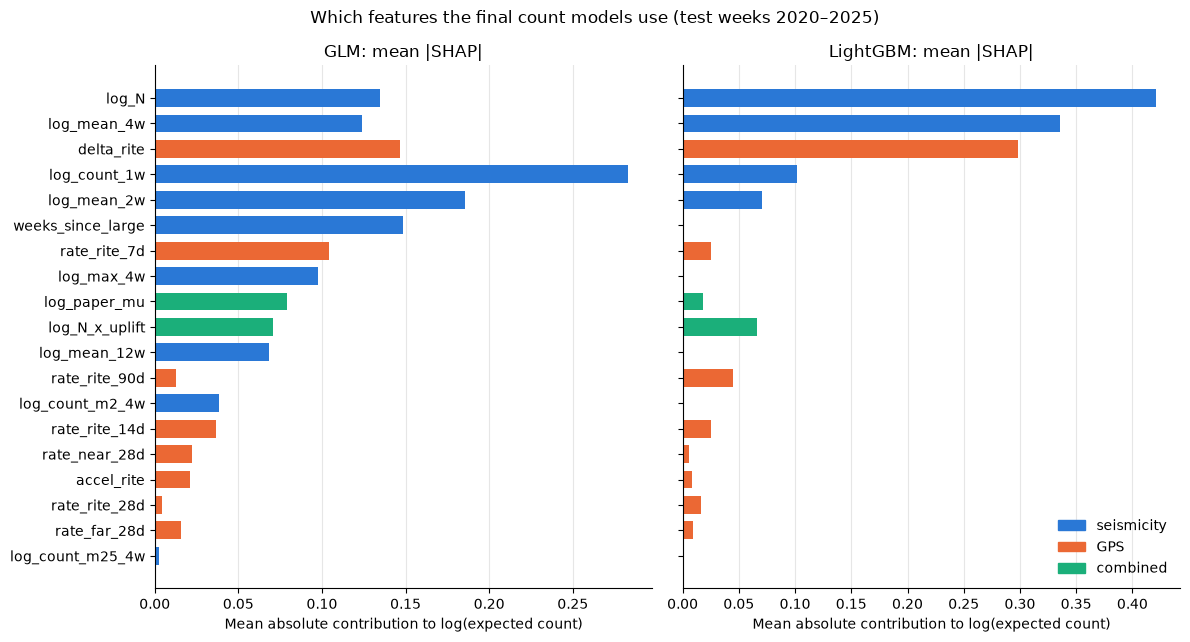

In [27]:
importance = pd.DataFrame({"GLM": glm_shap.abs().mean(), "LightGBM": lgbm_shap.abs().mean()})
order = importance.max(axis=1).sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
for ax, model in zip(axes, ["GLM", "LightGBM"]):
    values = importance.loc[order, model]
    ax.barh(order, values, color=[group_colours[feature_group[f]] for f in order], height=0.7)
    ax.set_title(f"{model}: mean |SHAP|")
    ax.set_xlabel("Mean absolute contribution to log(expected count)")
    ax.grid(True, axis="x", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colours.values()]
axes[1].legend(handles, group_colours.keys(), frameon=False, loc="lower right")
fig.suptitle("Which features the final count models use (test weeks 2020–2025)")
plt.tight_layout()
plt.show()

In [28]:
# Share of all attribution per feature group, and how correlated the top GPS feature is with
# the cumulative count over the training weeks.
shares = pd.DataFrame({model: imp.groupby(feature_group).sum() / imp.sum()
                       for model, imp in [("GLM", importance["GLM"]), ("LightGBM", importance["LightGBM"])]})
print(f"Correlation of delta_rite with log_N over 2013–2025: {final_train['delta_rite'].corr(final_train['log_N']):.3f}")
shares.round(2)

Correlation of delta_rite with log_N over 2013–2025: 0.998


,GLM,LightGBM
GPS,0.23,0.30
combined,0.09,0.06
seismicity,0.68,0.64


**How each feature's value moves the LightGBM forecast.** Each dot is one test week: its position is the feature's contribution, its colour the feature's value (red = high, blue = low).

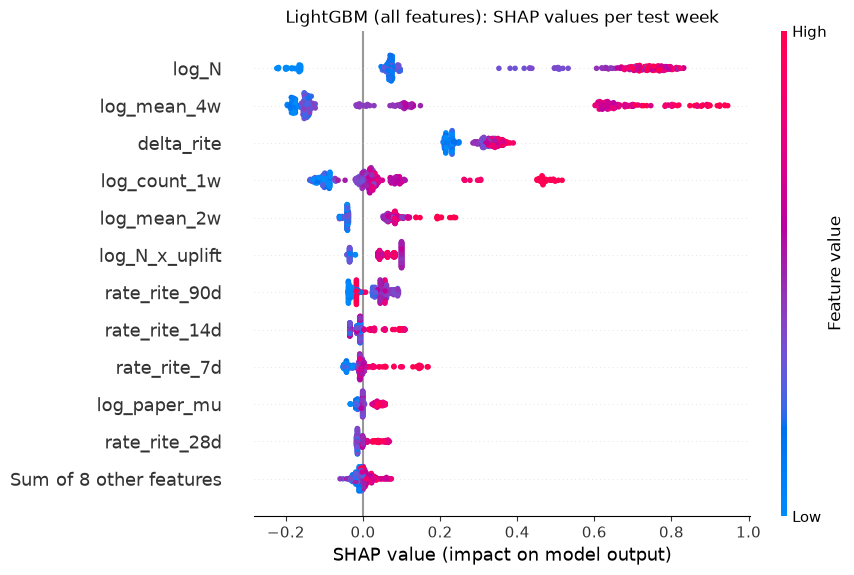

In [29]:
explanation = shap.Explanation(values=lgbm_shap.to_numpy(), base_values=np.full(len(test), explainer.expected_value),
                               data=X_test.to_numpy(), feature_names=ALL_FEATURES)
shap.plots.beeswarm(explanation, max_display=12, show=False)
plt.title("LightGBM (all features): SHAP values per test week")
plt.show()

**Over time.** The LightGBM contributions summed by group, week by week in 2023–2025, next to the observed weekly count (log scale). It shows which kind of information moves the forecast when.

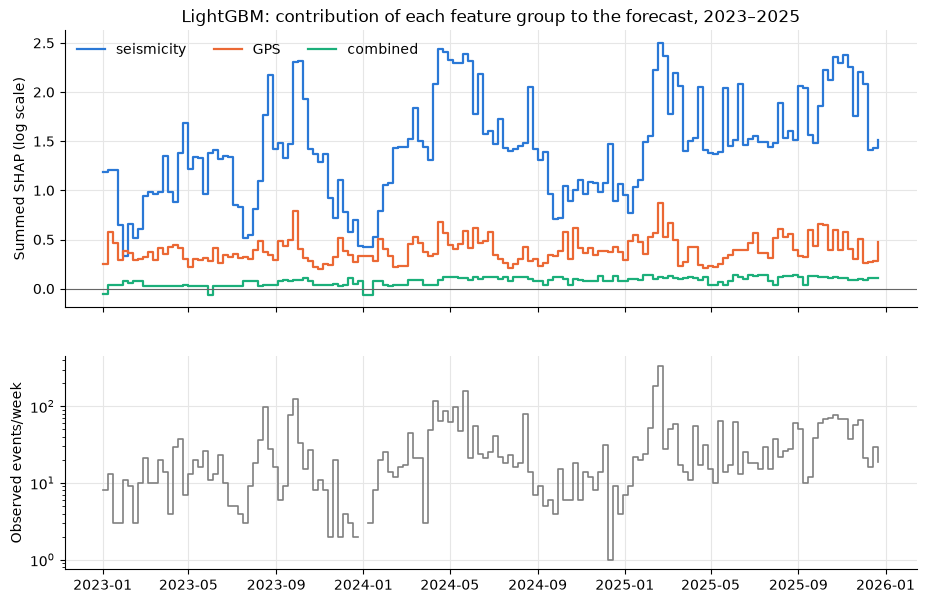

In [30]:
by_group = lgbm_shap.T.groupby(feature_group).sum().T.loc["2023-01-01":]
fig, (ax_c, ax_n) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
for group, colour in group_colours.items():
    ax_c.plot(by_group.index, by_group[group], drawstyle="steps-post", linewidth=1.6, color=colour, label=group)
ax_c.axhline(0, color="0.4", linewidth=0.8)
ax_c.set_ylabel("Summed SHAP (log scale)")
ax_c.set_title("LightGBM: contribution of each feature group to the forecast, 2023–2025")
ax_c.legend(frameon=False, loc="upper left", ncol=3)
shown = test.loc["2023-01-01":, "count"]
ax_n.plot(shown.index, shown.where(shown > 0), drawstyle="steps-post", color="0.5", linewidth=1.2)
ax_n.set_yscale("log")
ax_n.set_ylabel("Observed events/week")
for ax in (ax_c, ax_n):
    ax.grid(True, which="major", color="0.9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What SHAP shows:**

- **Both models rely mostly on seismicity** (about two-thirds of all attribution: 68% GLM, 64% LightGBM). The GLM leans on the most recent counts (last week, last 2 weeks) and on how long since the last M ≥ 3; LightGBM on the cumulative count and the 4-week mean.
- **GPS gets about a quarter of the credit (23% GLM, 30% LightGBM), almost all through the uplift level `delta_rite`.** But over the training weeks `delta_rite` and the cumulative count `log_N` are almost perfectly correlated (0.99+): both are smooth, rising trends, and since 2012 log N has grown almost linearly with uplift (phase 4, the paper's own relationship). The models use one or the other to represent the same long-term trend, and SHAP splits the credit between them arbitrarily. That's why the ablation (training without GPS) lost nothing: `log_N` takes over.
- **Short-term uplift rates are used a little, in the expected direction:** faster uplift over 7–14 days nudges the forecast up (beeswarm: red dots to the right of `rate_rite_7d` and `rate_rite_14d`). But the effect is small (mean |SHAP| about 0.1 or less) and didn't improve forecasts on unseen weeks (sections 2–3). The far-station rate and the acceleration, which phase 6 step 1 found to be mostly network noise, get almost nothing.
- **Over time,** the seismicity contribution swings with the swarms (between about +0.5 and +2.5 on the log scale), while the GPS contribution is a nearly steady offset (mostly +0.3 to +0.5) with small bumps, for example in early 2025: GPS sets the background level, seismicity follows the swarms.

## Summary of phase 6

| Question | Answer |
|---|---|
| Can ML beat the baselines for weekly counts? | Yes, a little: the Poisson GLM on seismicity features (deviance 13.4 / 22.5 against 14.8 / 24.1), though the gain is within noise. LightGBM does not (14.8): the data prefer the simplest models. |
| Do GPS features improve weekly count forecasts? | No measurable gain, in either model family. |
| Can ML beat the baselines for P(M ≥ 3 next week)? | Only after fixing the over-confident count conversion: a recalibrated forecast from the 4-week count, trained on the last 3 years, beats the bar and climatology on every score (2024–2025 Brier 0.203 against 0.217 and 0.209), again within noise. |
| Do GPS features improve P(M ≥ 3)? | No: they make forecasts significantly worse, raw or noise-corrected. |
| Why doesn't GPS help? | Its slow part (uplift level) duplicates the cumulative count, which the models already have; its fast part (weekly uplift rate) is weak and dominated by GPS noise, and its link to seismicity is simultaneous rather than leading (phase 4). |

**Answer to the research question, so far:** with weekly resolution and this data, GPS uplift adds no measurable forecasting skill beyond past seismicity. Uplift explains the long-term growth of seismicity well (phase 5), but that growth is already visible in the earthquake counts themselves.

Phase 7 (agreed in discussion) will strengthen these conclusions: ranking and calibration scores for every forecaster, the steady 2024–2025 period alongside 2020–2025, a full predictive distribution for counts (negative binomial), the power of the tests, and sensitivity to training window, horizon and magnitude threshold.